--- Step 1 Complete: Libraries Imported ---
--- Step 2 Complete: OOP & Comprehensions verified. Generated 100 Employee IDs. ---
--- Step 3 Complete: NumPy operations executed successfully. ---
Missing values before cleaning:
Emp_ID             0
Department         0
Base_Salary        0
Adjusted_Salary    0
Performance        5
Seniority          0
dtype: int64

--- Step 4 Complete: Pandas DataFrame Cleaned, Merged, and Grouped ---
    Department Adjusted_Salary        Bonus              Emp_ID
                          mean         mean          sum  count
0  Engineering    74345.600769  5387.582231  140077.1380     26
1           HR    70755.337857  5871.062821  164389.7590     28
2    Marketing    70758.447895  5141.188184   97682.5755     19
3        Sales    67988.319259  5379.631037  145250.0380     27


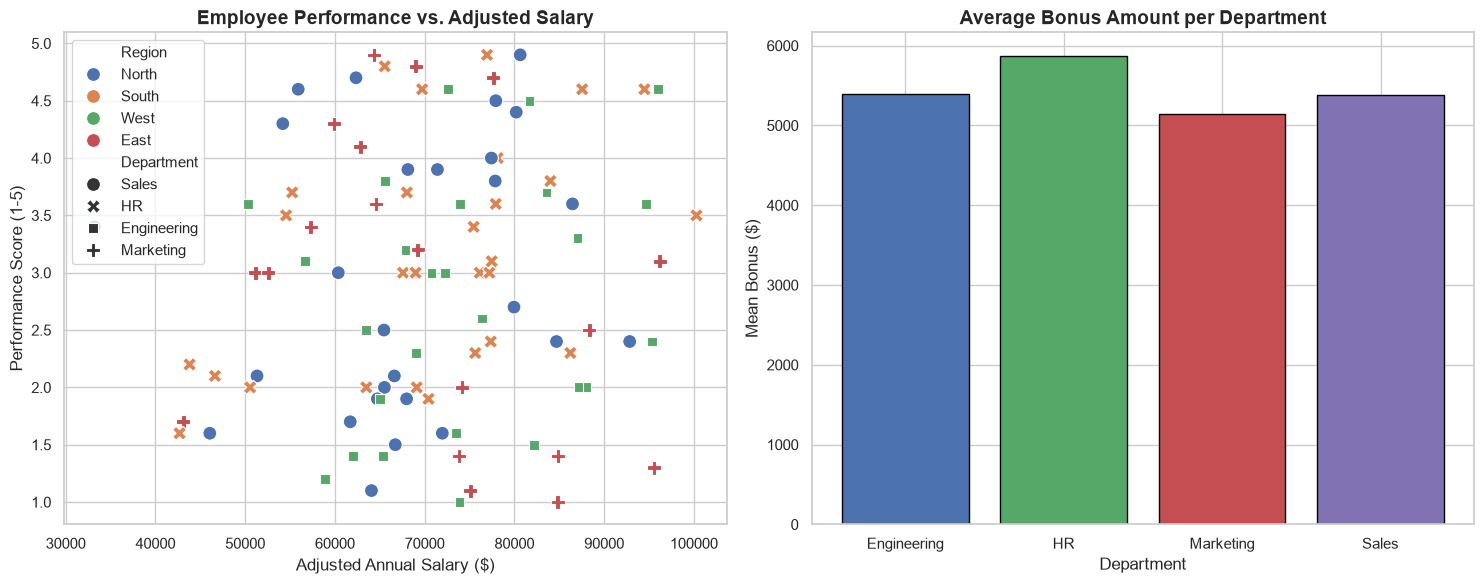

--- Step 5 Complete: Visualizations Rendered Successfully ---


In [1]:
# ==========================================
# STEP 1: IMPORT CORE LIBRARIES
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting styling
sns.set_theme(style="whitegrid")
%matplotlib inline

print("--- Step 1 Complete: Libraries Imported ---")

# ==========================================
# STEP 2: PYTHON ESSENTIALS & OBJECT-ORIENTED PROGRAMMING (OOP)
# ==========================================
# 1. Standard Function
def calculate_bonus(salary, performance_score):
    """Calculates employee bonus based on performance score."""
    if performance_score >= 4.5:
        return salary * 0.15
    elif performance_score >= 3.5:
        return salary * 0.10
    else:
        return salary * 0.05

# 2. Object-Oriented Programming (OOP)
class DataGenerator:
    """A class to generate mock corporate data dynamically."""
    def __init__(self, num_records=100):
        self.num_records = num_records

    def generate_employee_ids(self):
        # List comprehension to generate unique structured strings
        return [f"EMP_{i:03d}" for i in range(1, self.num_records + 1)]

# Initialize class and use it
generator = DataGenerator(num_records=100)
emp_ids = generator.generate_employee_ids()

# 3. Dictionary Comprehension
# Creating a sample reference map for department budgets
departments = ['Sales', 'Engineering', 'Marketing', 'HR']
dept_budget_map = {dept: np.random.randint(50000, 150000) for dept in departments}

print(f"--- Step 2 Complete: OOP & Comprehensions verified. Generated {len(emp_ids)} Employee IDs. ---")


# ==========================================
# STEP 3: NUMPY (Arrays, Vectorized Ops, Broadcasting)
# ==========================================
np.random.seed(42)  # For reproducibility

# 1. Creating Numpy Arrays
base_salaries = np.random.normal(loc=70000, scale=15000, size=100).round(2)
perf_scores = np.random.uniform(low=1.0, high=5.0, size=100).round(1)

# 2. Broadcasting & Vectorized Operations
# Suppose every employee gets a flat inflation adjustment of $2,500 (Broadcasting)
adjusted_salaries = base_salaries + 2500

# Vectorized operation: combining arrays element-wise without traditional python loops
experience_years = np.random.randint(1, 15, size=100)
seniority_metric = (adjusted_salaries * 0.0001) + (experience_years * 1.5)

print("--- Step 3 Complete: NumPy operations executed successfully. ---")


# ==========================================
# STEP 4: PANDAS (DataFrames, Cleaning, Merging, Groupby)
# ==========================================
# 1. Constructing the Primary DataFrame
df_employees = pd.DataFrame({
    'Emp_ID': emp_ids,
    'Department': np.random.choice(departments, size=100),
    'Base_Salary': base_salaries,
    'Adjusted_Salary': adjusted_salaries,
    'Performance': perf_scores,
    'Seniority': seniority_metric
})

# Artificially inject a few missing values to demonstrate data cleaning
df_employees.loc[np.random.choice(100, 5), 'Performance'] = np.nan

# 2. Data Cleaning
print(f"Missing values before cleaning:\n{df_employees.isnull().sum()}\n")
# Handle missing data using Pandas tracking functions
df_employees['Performance'] = df_employees['Performance'].fillna(df_employees['Performance'].median())

# 3. Merging DataFrames
# Creating a second regional mapping dataframe to merge
df_regions = pd.DataFrame({
    'Department': departments,
    'Region': ['North', 'West', 'East', 'South']
})
# SQL-style Join / Merge
df_final = pd.merge(df_employees, df_regions, on='Department', how='inner')

# Apply our custom Python function using pandas .apply()
df_final['Bonus'] = df_final.apply(lambda row: calculate_bonus(row['Adjusted_Salary'], row['Performance']), axis=1)

# 4. Groupby & Aggregation
summary_stats = df_final.groupby('Department').agg({
    'Adjusted_Salary': 'mean',
    'Bonus': ['mean', 'sum'],
    'Emp_ID': 'count'
}).reset_index()

print("--- Step 4 Complete: Pandas DataFrame Cleaned, Merged, and Grouped ---")
print(summary_stats.head())


# ==========================================
# STEP 5: DATA VISUALIZATION (Matplotlib & Seaborn)
# ==========================================
# Setting up subplots to show dual insights cleanly
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Seaborn Scatter Plot (Insights on Salary vs Performance color-coded by Region)
sns.scatterplot(
    data=df_final, 
    x='Adjusted_Salary', 
    y='Performance', 
    hue='Region', 
    style='Department',
    palette='deep', 
    s=100,
    ax=axes[0]
)
axes[0].set_title('Employee Performance vs. Adjusted Salary', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Adjusted Annual Salary ($)')
axes[0].set_ylabel('Performance Score (1-5)')

# 2. Matplotlib Bar Plot (Visualization of Aggregate Grouped Data)
departments_list = summary_stats['Department']
average_bonus = summary_stats[('Bonus', 'mean')]

axes[1].bar(departments_list, average_bonus, color=['#4C72B0', '#55A868', '#C44E52', '#8172B3'], edgecolor='black')
axes[1].set_title('Average Bonus Amount per Department', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Department')
axes[1].set_ylabel('Mean Bonus ($)')

plt.tight_layout()
plt.show()

print("--- Step 5 Complete: Visualizations Rendered Successfully ---")
